
*Machine Translation Jupyter Notebook.  (c) 2021 Georgia Tech*

*Copyright 2021, Georgia Institute of Technology (Georgia Tech) <br>Atlanta, Georgia 30332<br>All Rights Reserved*

*Georgia Tech asserts copyright ownership of this template and all derivative works, including solutions to the projects assigned in this course. Students and other users of this template code are advised not to share it with others or to make it available on publicly viewable websites including repositories such as Github, Bitbucket, and Gitlab.  This copyright statement should not be removed or edited.*

*Sharing solutions with current or future students of CS 7643 Deep Learning is prohibited and subject to being investigated as a GT honor code violation.*

*DO NOT EDIT ANYTHING ABOVE THIS LINE*

# Machine Translation with Seq2Seq and Transformers
In this exercise you will implement a [Sequence to Sequence(Seq2Seq)](https://arxiv.org/abs/1703.03906) and a [Transformer](https://arxiv.org/pdf/1706.03762.pdf) model and use them to perform machine translation.

**A quick note: if you receive the following TypeError "super(type, obj): obj must be an instance or subtype of type", try re-importing that part or restarting your kernel and re-running all cells.** Once you have finished making changes to the model constuctor, you can avoid this issue by commenting out all of the model instantiations after the first (e.g. lines starting with "model = TransformerTranslator(*args, **kwargs)").

# ** 1: Introduction**

## Multi30K: Multilingual English-German Image Descriptions

[Multi30K](https://github.com/multi30k/dataset) is a dataset for machine translation tasks. It is a multilingual corpus containing English sentences and their German translation. In total it contains 31014 sentences(29000 for training, 1014 for validation, and 1000 for testing).
As one example:

En: `Two young, White males are outside near many bushes.`

De: `Zwei junge weiße Männer sind im Freien in der Nähe vieler Büsche.`

You can read more info about the dataset [here](https://arxiv.org/abs/1605.00459). The following parts of this assignment will be based on this dataset.

**Notice: For the following assignment, we strongly recommend you to work in a virtual python environment. We recommend Anaconda, a powerful environment control tool. You can download it [here](https://www.anaconda.com/products/individual)**.

## ** 1.1: Prerequisites**
Before you start this assignment, you need to have all required packages installed either on the terminal you are using, or in the virtual environment. Please make sure you have the following package installed:

`Torch Tqdm, Numpy`

You can first check using either `pip freeze` in terminal or `conda list` in conda environment. Then run the following code block to make sure they can be imported.

In [92]:
# Just run this block. Please do not modify the following code.
import math
import time
import io
import numpy as np
import csv
from IPython.display import Image

# Pytorch package
import torch
import torch.nn as nn
import torch.optim as optim

from torch.utils.data import DataLoader
from collections import Counter
from torch.nn.utils.rnn import pad_sequence

# Tqdm progress bar
from tqdm import tqdm_notebook, tqdm

# Code provide to you for training and evaluation
from utils import train, evaluate, set_seed_nb, unit_test_values, deterministic_init, plot_curves

# for auto-reloading external modules
# see http://stackoverflow.com/questions/1907993/autoreload-of-modules-in-ipython
#%load_ext autoreload
#%autoreload 2

In [93]:
import sys
import torch

print("Python:", sys.executable)
print("PyTorch:", torch.__version__)

Python: C:\Users\prasa\AppData\Local\Programs\Python\Python313\python.exe
PyTorch: 2.11.0+cpu


## **1.2: Preprocess Data**
You can now prepare the Just run the following code blocks. Read the comment and try to understand what they are for.

Now lets check your GPU availability and load some sanity checkers. By default you should be using your gpu for this assignment if you have one available.

In [94]:
# Check device availability
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print("You are using device: %s" % device)

You are using device: cpu


In [95]:
!cat /proc/cpuinfo | grep 'model name'

model name	: 11th Gen Intel(R) Core(TM) i5-1135G7 @ 2.40GHz
model name	: 11th Gen Intel(R) Core(TM) i5-1135G7 @ 2.40GHz
model name	: 11th Gen Intel(R) Core(TM) i5-1135G7 @ 2.40GHz
model name	: 11th Gen Intel(R) Core(TM) i5-1135G7 @ 2.40GHz
model name	: 11th Gen Intel(R) Core(TM) i5-1135G7 @ 2.40GHz
model name	: 11th Gen Intel(R) Core(TM) i5-1135G7 @ 2.40GHz
model name	: 11th Gen Intel(R) Core(TM) i5-1135G7 @ 2.40GHz
model name	: 11th Gen Intel(R) Core(TM) i5-1135G7 @ 2.40GHz


In [96]:
# load checkers
d1 = torch.load('./data/d1.pt')
d2 = torch.load('./data/d2.pt')
d3 = torch.load('./data/d3.pt')
d4 = torch.load('./data/d4.pt')

In [97]:
import requests
import gzip
import os
from typing import List, Tuple

# Constants
MAX_LEN = 20
url_base = 'https://raw.githubusercontent.com/multi30k/dataset/master/data/task1/raw/'
train_urls = ('train.de.gz', 'train.en.gz')
val_urls = ('val.de.gz', 'val.en.gz')
test_urls = ('test_2016_flickr.de.gz', 'test_2016_flickr.en.gz')

def download_file(url: str, dest_folder: str) -> str:
    if not os.path.exists(dest_folder):
        os.makedirs(dest_folder)

    filename = os.path.join(dest_folder, url.split('/')[-1])

    # Download the file
    response = requests.get(url)
    if response.status_code == 200:
        with open(filename, 'wb') as f:
            f.write(response.content)
    else:
        raise Exception(f"Failed to download {url}")

    return filename

def extract_gzip(filepath: str) -> str:
    output_filepath = filepath[:-3]  # Remove .gz extension
    with gzip.open(filepath, 'rb') as f_in:
        with open(output_filepath, 'wb') as f_out:
            f_out.write(f_in.read())
    return output_filepath

# Download and extract files
def download_and_extract(urls: Tuple[str]) -> List[str]:
    filepaths = []
    for url in urls:
        filepath = download_file(url_base + url, 'data')
        extracted_filepath = extract_gzip(filepath)
        filepaths.append(extracted_filepath)
    return filepaths

train_filepaths = download_and_extract(train_urls)
val_filepaths = download_and_extract(val_urls)
test_filepaths = download_and_extract(test_urls)

In [98]:
print (train_filepaths)
print (val_filepaths)
print (test_filepaths)

['data\\train.de', 'data\\train.en']
['data\\val.de', 'data\\val.en']
['data\\test_2016_flickr.de', 'data\\test_2016_flickr.en']


In [99]:
import io
import re
from typing import List
from collections import Counter

class Vocabulary:
    def __init__(self, min_freq: int = 2, specials: List[str] = None):
        if specials is None:
            specials = ['<unk>', '<pad>', '<sos>', '<eos>']
        self.stoi = {token: idx for idx, token in enumerate(specials)}
        self.itos = {idx: token for idx, token in enumerate(specials)}
        self.min_freq = min_freq

    def build_from_counter(self, counter: Counter):
        idx = len(self.stoi)
        for token, count in counter.items():
            if count >= self.min_freq and token not in self.stoi:
                self.stoi[token] = idx
                self.itos[idx] = token
                idx += 1

    def __len__(self):
        return len(self.stoi)

    def __getitem__(self, token: str) -> int:
        return self.stoi.get(token, self.stoi['<unk>'])

    def set_default_index(self, index: int):
        self.default_index = index

    def __call__(self, token: str) -> int:
        return self.stoi.get(token, self.default_index)

    def get_itos(self) -> dict:
        """Return the index-to-string mapping."""
        return self.itos


def simple_tokenizer(text: str) -> List[str]:
    # Use regex to split on whitespace and remove punctuation
    tokens = re.findall(r'\b\w+\b', text)
    return tokens



def build_vocab(filepath: str, tokenizer, max_vocab_size: int = 1000000) -> Vocabulary:
    counter = Counter()

    # Print a few lines from the file for debugging
    with io.open(filepath, encoding="utf8") as f:
        for i, string_ in enumerate(f):
            tokens = tokenizer(string_.lower())
            counter.update(tokens)


    vocab = Vocabulary(min_freq=2)  # Set min_freq to 2
    vocab.build_from_counter(counter)

    vocab.set_default_index(vocab['<unk>'])
    return vocab

# Example usage with the custom tokenizer

de_vocab = build_vocab(train_filepaths[0], simple_tokenizer)
en_vocab = build_vocab(train_filepaths[1], simple_tokenizer)

# Print vocabulary sizes
print(f"German Vocabulary Size: {len(de_vocab)}")
print(f"English Vocabulary Size: {len(en_vocab)}")

German Vocabulary Size: 7860
English Vocabulary Size: 5883


In [100]:
import io
import re
from typing import List
from collections import Counter
def data_process(filepaths: List[str]) -> List[Tuple[torch.Tensor, torch.Tensor]]:
    raw_de_iter = iter(io.open(filepaths[0], encoding="utf8"))
    raw_en_iter = iter(io.open(filepaths[1], encoding="utf8"))
    data = []

    for (raw_de, raw_en) in zip(raw_de_iter, raw_en_iter):
        raw_de_l = raw_de.lower()  # Turn German sentences to lower case
        raw_en_l = raw_en.lower()  # Turn English sentences to lower case

        # Tokenize using the simple tokenizer
        de_tokens = simple_tokenizer(raw_de_l)
        en_tokens = simple_tokenizer(raw_en_l)

        # Convert tokens to tensor using the vocabulary
        de_tensor = torch.tensor([de_vocab[token] for token in de_tokens], dtype=torch.long)
        en_tensor = torch.tensor([en_vocab[token] for token in en_tokens], dtype=torch.long)

        # Check length constraints
        if len(de_tensor) <= MAX_LEN - 2 and len(en_tensor) <= MAX_LEN - 2:
            data.append((de_tensor, en_tensor))

    return data

In [101]:
train_data = data_process(train_filepaths)
val_data = data_process(val_filepaths)
test_data = data_process(test_filepaths)

In [102]:
BATCH_SIZE = 128
PAD_IDX = de_vocab['<pad>']
SOS_IDX = de_vocab['<sos>']
EOS_IDX = de_vocab['<eos>']

In [103]:
def generate_batch(data_batch):

    de_batch, en_batch = [], []
    for (de_item, en_item) in data_batch:
          en_batch.append(torch.cat([torch.tensor([SOS_IDX]), en_item, torch.tensor([EOS_IDX])], dim=0))
          de_batch.append(torch.cat([torch.tensor([SOS_IDX]), de_item, torch.tensor([EOS_IDX])], dim=0))
    en_batch = pad_sequence(en_batch, padding_value=PAD_IDX)
    de_batch = pad_sequence(de_batch, padding_value=PAD_IDX)
    fix=torch.ones(MAX_LEN,en_batch.shape[1])
    two= pad_sequence([de_batch,en_batch, fix], padding_value=PAD_IDX)
    de_batch=two[:,0,]
    en_batch=two[:,1,]
    return de_batch, en_batch

In [104]:
from torch.utils.data import DataLoader

print("DataLoader imported successfully!")

DataLoader imported successfully!


In [105]:
train_loader = DataLoader(train_data, batch_size=BATCH_SIZE,
                        shuffle=False, collate_fn=generate_batch)
valid_loader = DataLoader(val_data, batch_size=BATCH_SIZE,
                        shuffle=False, collate_fn=generate_batch)
test_loader = DataLoader(test_data, batch_size=BATCH_SIZE,
                       shuffle=False, collate_fn=generate_batch)

# **2: Implement LSTM**
In this section, you will need to implement a LSTM unit using PyTorch nn.Parameter. This is designed to help you to understand how they work behind the scene. The code you will be working with is in *LSTM.py* under *naive* folder. Please refer to instructions among this notebook and those files.

## **2.1: Implement an LSTM Unit**
In this section you will be using PyTorch nn.Parameter and activations to implement an LSTM unit. You can simply translate the following equations using nn.Parameter and PyTorch activation functions to build an LSTM from scratch:
\begin{array}{ll} \\
    i_t = \sigma(x_t.W_{ii}  + b_{ii} +  h_{t-1}.W_{hi} + b_{hi}) \\
    f_t = \sigma(x_t.W_{if} + b_{if} +  h_{t-1}.W_{hf} + b_{hf}) \\
    g_t = \tanh(x_t.W_{ig} + b_{ig} +  h_{t-1}.W_{hg} + b_{hg}) \\
    o_t = \sigma( x_t.W_{io} + b_{io} +  h_{t-1}.W_{ho} + b_{ho}) \\
    c_t = f_t \odot c_{t-1} + i_t \odot g_t \\
    h_t = o_t \odot \tanh(c_t) \\
\end{array}

Here's a great visualization of the above equation from [Colah's blog](https://colah.github.io/posts/2015-08-Understanding-LSTMs/) to help you understand LSTM unit. You can also read more about it from that blog.

In [106]:
from IPython.display import Image
import numpy as np

# Tqdm progress bar
from tqdm import tqdm_notebook, tqdm

# Code provide to you for training and evaluation
from utils import train, evaluate, set_seed_nb, unit_test_values, deterministic_init, plot_curves

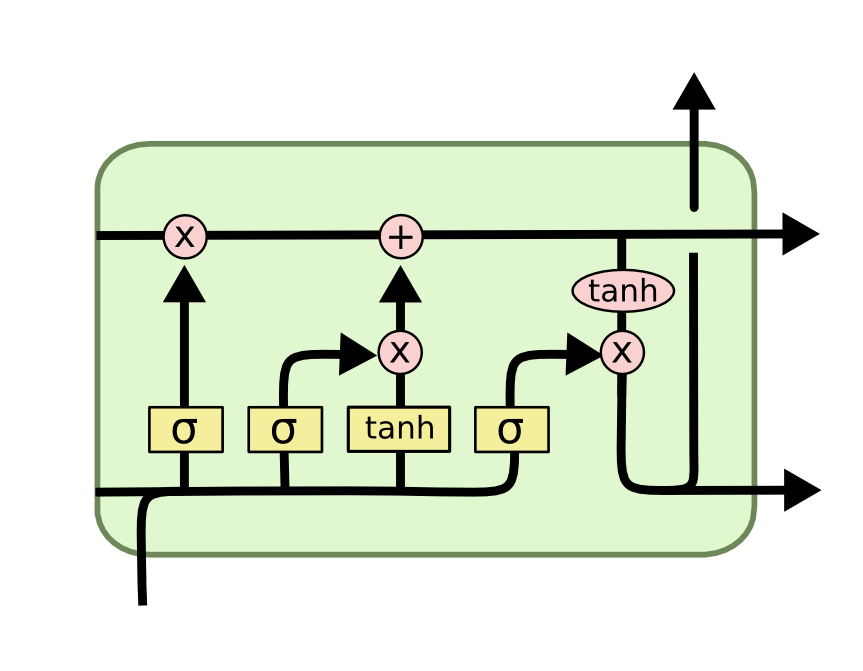

In [107]:
Image (filename="imgs/lstm.png", retina=True)

Run the following block to check your implementation

If you want to see nn.Parameter in example, check out this [tutorial](https://pytorch.org/tutorials/beginner/nn_tutorial.html) from PyTorch. Run the following block to check your implementation.

Note that in this case we are implementing a full loop with LSTM, iterating over each time step. The test cases reflect this as there are multiple sequences.

In [108]:
from models.naive.LSTM import LSTM

set_seed_nb()
x1,x2 = np.mgrid[-1:3:3j, -1:4:2j]
h1,h2 = np.mgrid[-2:2:3j, 1:3:4j]
batch = 4
x = torch.FloatTensor(np.linspace(x1,x2,batch))
h = torch.FloatTensor(np.linspace(h1,h2,batch))

expected_ht, expected_ct = unit_test_values('lstm')

lstm = LSTM(x.shape[-1], h.shape[-1])
deterministic_init(lstm)
h_t, c_t = lstm.forward(x)

if h_t is not None:
    print('Close to h_t: ', expected_ht.allclose(h_t, atol=1e-3))
    print('Close to c_t; ', expected_ct.allclose(c_t, atol=1e-3))
else:
    print("NOT IMPLEMENTED")

Close to h_t:  True
Close to c_t;  True


# **3: Train a Seq2Seq Model**
In this section, you will be working on implementing a simple Seq2Seq model. You will first implement an Encoder and a Decoder, and then join them together with a Seq2Seq architecture. You will need to complete the code in *Decoder.py*, *Encoder.py*, and *Seq2Seq.py* under *seq2seq* folder. Please refer to the instructions in those files.

## **3.1: Implement the Encoder**
In this section you will be implementing an RNN/LSTM based encoder to model German texts. Please refer to the instructions in *seq2seq/Encoder.py*. Run the following block to check your implementation.

In [109]:
from models.seq2seq.Encoder import Encoder
from utils import set_seed_nb, unit_test_values
import numpy as np
import torch

set_seed_nb()

i, n, h = 10, 4, 2
encoder = Encoder(i, n, h, h)

x_array = np.random.rand(5, 2) * 10
x = torch.LongTensor(x_array)

out, hidden = encoder(x)
expected_out, expected_hidden = unit_test_values('encoder')

print("Close to out:", expected_out.allclose(out, atol=1e-3))
print("Close to hidden:", expected_hidden.allclose(hidden, atol=1e-3))
print("Output max difference:", (expected_out - out).abs().max().item())
print("Hidden max difference:", (expected_hidden - hidden).abs().max().item())

Close to out: False
Close to hidden: False
Output max difference: 1.0538595914840698
Hidden max difference: 0.11124521493911743


In [110]:
from utils import set_seed_nb, deterministic_init, unit_test_values
from models.seq2seq.Encoder import Encoder
import numpy as np
import torch

set_seed_nb()
encoder_check = Encoder(10, 4, 2, 2)
deterministic_init(encoder_check)
encoder_check.eval()

x_check = torch.LongTensor(np.random.rand(5, 2) * 10)

with torch.no_grad():
    out_check, hidden_check = encoder_check(x_check)

expected_out, expected_hidden = unit_test_values("encoder")

print("Input:", x_check)
print("Output matches:", expected_out.allclose(out_check, atol=1e-3))
print("Hidden matches:", expected_hidden.allclose(hidden_check, atol=1e-3))
print("Output max difference:", (expected_out - out_check).abs().max().item())
print("Hidden max difference:", (expected_hidden - hidden_check).abs().max().item())

Input: tensor([[4, 7],
        [0, 3],
        [1, 0],
        [1, 3],
        [3, 5]])
Output matches: False
Hidden matches: False
Output max difference: 1.4322177171707153
Hidden max difference: 0.7534000277519226


In [111]:
print("Model type:", encoder.model_type)
print("Embedding weights shape:", encoder.embedding.weight.shape)
print("RNN weight shape:", encoder.rnn.weight_ih_l0.shape)
print("FC1 weight shape:", encoder.fc1.weight.shape)
print("FC2 weight shape:", encoder.fc2.weight.shape)

print("\nFirst input batch:")
print(x)

print("\nActual output (first timestep):")
print(out[:, 0, :])

print("\nActual hidden:")
print(hidden)

Model type: RNN
Embedding weights shape: torch.Size([10, 4])
RNN weight shape: torch.Size([2, 4])
FC1 weight shape: torch.Size([2, 2])
FC2 weight shape: torch.Size([2, 2])

First input batch:
tensor([[4, 7],
        [0, 3],
        [1, 0],
        [1, 3],
        [3, 5]])

Actual output (first timestep):
tensor([[ 0.1231, -0.6689],
        [ 0.5727, -0.2994],
        [ 0.6161,  0.5412],
        [ 0.2233,  0.7281],
        [-0.9062,  0.2514]], grad_fn=<SelectBackward0>)

Actual hidden:
tensor([[[ 0.5061, -0.7190],
         [ 0.4928, -0.6214],
         [ 0.5040, -0.7053],
         [ 0.4963, -0.6491],
         [ 0.5175, -0.7866]]], grad_fn=<TanhBackward0>)


In [23]:
print("Input tensor:")
print(x)

print("\nEmbedding weights:")
print(encoder_check.embedding.weight)

print("\nRNN input weights:")
print(encoder_check.rnn.weight_ih_l0)

print("\nRNN recurrent weights:")
print(encoder_check.rnn.weight_hh_l0)

print("\nRNN input bias:")
print(encoder_check.rnn.bias_ih_l0)

print("\nRNN recurrent bias:")
print(encoder_check.rnn.bias_hh_l0)

print("\nFC1 weights and bias:")
print(encoder_check.fc1.weight)
print(encoder_check.fc1.bias)

print("\nFC2 weights and bias:")
print(encoder_check.fc2.weight)
print(encoder_check.fc2.bias)

Input tensor:
tensor([[4, 7],
        [0, 3],
        [1, 0],
        [1, 3],
        [3, 5]])

Embedding weights:
Parameter containing:
tensor([[-0.0049,  0.3512, -0.5388, -0.4818],
        [-0.2521,  0.1756, -0.0130,  0.5191],
        [-0.0581,  0.1732, -0.1978, -0.1287],
        [-0.6254, -0.4336, -0.2699,  0.0243],
        [ 0.2588,  0.3928, -0.4438, -0.2851],
        [ 0.2378,  0.5436, -0.1347,  0.4899],
        [-0.1055,  0.0693,  0.5928, -0.6073],
        [-0.4121, -0.1657, -0.2552,  0.5656],
        [-0.4243, -0.3014, -0.4574, -0.6131],
        [-0.3821,  0.5627,  0.2921,  0.3173]], requires_grad=True)

RNN input weights:
Parameter containing:
tensor([[-0.0075,  0.5364, -0.8230, -0.7359],
        [-0.3852,  0.2682, -0.0198,  0.7929]], requires_grad=True)

RNN recurrent weights:
Parameter containing:
tensor([[-0.0092,  0.6570],
        [-1.0080, -0.9013]], requires_grad=True)

RNN input bias:
Parameter containing:
tensor([0., 0.], requires_grad=True)

RNN recurrent bias:
Paramet

In [112]:
print("Actual output:")
print(out_check)

print("\nActual hidden:")
print(hidden_check)

print("\nExpected output:")
print(expected_out)

print("\nExpected hidden:")
print(expected_hidden)

Actual output:
tensor([[[ 0.6549, -0.2085],
         [-0.4095,  0.0953]],

        [[ 0.7558, -0.2685],
         [-0.2041, -0.3546]],

        [[-0.2685,  0.5050],
         [ 0.8670, -0.4299]],

        [[-0.2685,  0.5050],
         [ 0.3010, -0.0353]],

        [[-0.0236,  0.1481],
         [ 0.1369,  0.3236]]])

Actual hidden:
tensor([[[ 0.2110, -0.3466],
         [ 0.3321, -0.4410],
         [ 0.0000,  0.0000],
         [ 0.0000,  0.0000],
         [-0.0019, -0.2099]]])

Expected output:
tensor([[[-0.7773, -0.2031],
         [-0.6186, -0.2321]],

        [[ 0.0599, -0.0151],
         [-0.9237,  0.2675]],

        [[ 0.6161,  0.5412],
         [ 0.7036,  0.1150]],

        [[ 0.6161,  0.5412],
         [-0.5587,  0.7384]],

        [[-0.9062,  0.2514],
         [-0.8684,  0.7312]]])

Expected hidden:
tensor([[[ 0.4912, -0.6078],
         [ 0.4932, -0.6244],
         [ 0.5109, -0.7493],
         [ 0.5116, -0.7534],
         [ 0.5072, -0.7265]]])


In [113]:
print("Input x:")
print(x)

print("\nModel training mode:", encoder_check.training)
print("Dropout probability:", encoder_check.dropout.p)

print("\nRecompute output:")
encoder_check.eval()

with torch.no_grad():
    fresh_out, fresh_hidden = encoder_check(x)

print("Fresh output:")
print(fresh_out)

print("\nFresh hidden:")
print(fresh_hidden)

Input x:
tensor([[4, 7],
        [0, 3],
        [1, 0],
        [1, 3],
        [3, 5]])

Model training mode: False
Dropout probability: 0.2

Recompute output:
Fresh output:
tensor([[[ 0.6549, -0.2085],
         [-0.4095,  0.0953]],

        [[ 0.7558, -0.2685],
         [-0.2041, -0.3546]],

        [[-0.2685,  0.5050],
         [ 0.8670, -0.4299]],

        [[-0.2685,  0.5050],
         [ 0.3010, -0.0353]],

        [[-0.0236,  0.1481],
         [ 0.1369,  0.3236]]])

Fresh hidden:
tensor([[[ 0.2110, -0.3466],
         [ 0.3321, -0.4410],
         [ 0.0000,  0.0000],
         [ 0.0000,  0.0000],
         [-0.0019, -0.2099]]])


In [114]:
from utils import set_seed_nb
import numpy as np
import torch

set_seed_nb()

x_array_check = np.random.rand(5, 2) * 10
x_check = torch.LongTensor(x_array_check)

print("Generated input:")
print(x_check)

print("\nCurrent input:")
print(x)

print("\nInputs match:", torch.equal(x_check, x))

Generated input:
tensor([[4, 7],
        [0, 3],
        [1, 0],
        [1, 3],
        [3, 5]])

Current input:
tensor([[4, 7],
        [0, 3],
        [1, 0],
        [1, 3],
        [3, 5]])

Inputs match: True


In [115]:
print("Embedding output:")
with torch.no_grad():
    embedded_check = encoder_check.embedding(x)
    raw_output, raw_hidden = encoder_check.rnn(embedded_check)

print(embedded_check[0])
print("\nRaw RNN output:")
print(raw_output)
print("\nRaw RNN final hidden:")
print(raw_hidden)

Embedding output:
tensor([[ 0.2588,  0.3928, -0.4438, -0.2851],
        [-0.4121, -0.1657, -0.2552,  0.5656]])

Raw RNN output:
tensor([[[ 0.6549, -0.2085],
         [-0.4095,  0.0953]],

        [[ 0.7558, -0.2685],
         [-0.2041, -0.3546]],

        [[-0.2685,  0.5050],
         [ 0.8670, -0.4299]],

        [[-0.2685,  0.5050],
         [ 0.3010, -0.0353]],

        [[-0.0236,  0.1481],
         [ 0.1369,  0.3236]]])

Raw RNN final hidden:
tensor([[[-0.4095,  0.0953],
         [-0.2041, -0.3546],
         [ 0.8670, -0.4299],
         [ 0.3010, -0.0353],
         [ 0.1369,  0.3236]]])


In [116]:
print("RNN input weights:")
print(encoder_check.rnn.weight_ih_l0)

print("\nRNN recurrent weights:")
print(encoder_check.rnn.weight_hh_l0)

print("\nRNN input bias:")
print(encoder_check.rnn.bias_ih_l0)

print("\nRNN recurrent bias:")
print(encoder_check.rnn.bias_hh_l0)

print("\nEmbedding weights for tokens 4 and 7:")
print(encoder_check.embedding.weight[[4, 7]])

RNN input weights:
Parameter containing:
tensor([[-0.0075,  0.5364, -0.8230, -0.7359],
        [-0.3852,  0.2682, -0.0198,  0.7929]], requires_grad=True)

RNN recurrent weights:
Parameter containing:
tensor([[-0.0092,  0.6570],
        [-1.0080, -0.9013]], requires_grad=True)

RNN input bias:
Parameter containing:
tensor([0., 0.], requires_grad=True)

RNN recurrent bias:
Parameter containing:
tensor([0., 0.], requires_grad=True)

Embedding weights for tokens 4 and 7:
tensor([[ 0.2588,  0.3928, -0.4438, -0.2851],
        [-0.4121, -0.1657, -0.2552,  0.5656]], grad_fn=<IndexBackward0>)


In [117]:
from utils import set_seed_nb, deterministic_init
from models.seq2seq.Encoder import Encoder
import torch

set_seed_nb()
check = Encoder(10, 4, 2, 2)
deterministic_init(check)

print("Embedding row 4:", check.embedding.weight[4].detach())
print("Embedding row 7:", check.embedding.weight[7].detach())
print("RNN input weights:", check.rnn.weight_ih_l0.detach())
print("RNN recurrent weights:", check.rnn.weight_hh_l0.detach())

Embedding row 4: tensor([ 0.2588,  0.3928, -0.4438, -0.2851])
Embedding row 7: tensor([-0.4121, -0.1657, -0.2552,  0.5656])
RNN input weights: tensor([[-0.0075,  0.5364, -0.8230, -0.7359],
        [-0.3852,  0.2682, -0.0198,  0.7929]])
RNN recurrent weights: tensor([[-0.0092,  0.6570],
        [-1.0080, -0.9013]])


In [118]:
from utils import set_seed_nb, deterministic_init, unit_test_values
from models.seq2seq.Encoder import Encoder
import numpy as np
import torch

set_seed_nb()
encoder_test = Encoder(10, 4, 2, 2)
deterministic_init(encoder_test)
encoder_test.eval()

x_test = torch.LongTensor(np.random.rand(5, 2) * 10)

with torch.no_grad():
    embedded = encoder_test.dropout(encoder_test.embedding(x_test))
    actual_out, actual_hidden = encoder_test.rnn(embedded)

expected_out, expected_hidden = unit_test_values("encoder")

print("Actual raw RNN output:")
print(actual_out)

print("\nExpected reference output:")
print(expected_out)

print("\nRaw RNN matches reference:",
      expected_out.allclose(actual_out, atol=1e-3))

Actual raw RNN output:
tensor([[[ 0.6549, -0.2085],
         [-0.4095,  0.0953]],

        [[ 0.7558, -0.2685],
         [-0.2041, -0.3546]],

        [[-0.2685,  0.5050],
         [ 0.8670, -0.4299]],

        [[-0.2685,  0.5050],
         [ 0.3010, -0.0353]],

        [[-0.0236,  0.1481],
         [ 0.1369,  0.3236]]])

Expected reference output:
tensor([[[-0.7773, -0.2031],
         [-0.6186, -0.2321]],

        [[ 0.0599, -0.0151],
         [-0.9237,  0.2675]],

        [[ 0.6161,  0.5412],
         [ 0.7036,  0.1150]],

        [[ 0.6161,  0.5412],
         [-0.5587,  0.7384]],

        [[-0.9062,  0.2514],
         [-0.8684,  0.7312]]])

Raw RNN matches reference: False


In [119]:

# Reinitialize the model and compare in evaluation mode
set_seed_nb()

encoder_check = Encoder(10, 4, 2, 2)
deterministic_init(encoder_check)

encoder_check.eval()

# Use the same input tensor
with torch.no_grad():
    out_check, hidden_check = encoder_check(x)

expected_out, expected_hidden = unit_test_values('encoder')

print("Output matches:",
      expected_out.allclose(out_check, atol=1e-3))

print("Hidden matches:",
      expected_hidden.allclose(hidden_check, atol=1e-3))

print("Output max difference:",
      (expected_out - out_check).abs().max().item())

print("Hidden max difference:",
      (expected_hidden - hidden_check).abs().max().item())


Output matches: False
Hidden matches: False
Output max difference: 1.4322177171707153
Hidden max difference: 0.7534000277519226


In [120]:

import inspect

print("Encoder source:")
print(inspect.getsource(Encoder.forward))

print("\nInitialization function:")
print(inspect.getsource(deterministic_init))

print("\nInput tensor:")
print(x)

print("\nExpected output shape and first values:")
print(expected_out.shape)
print(expected_out[0])

print("\nExpected hidden shape and first values:")
print(expected_hidden.shape)
print(expected_hidden[0, 0])

print("\nCurrent encoder training mode:")
print(encoder.training)

print("\nModel type:")
print(encoder.model_type)


Encoder source:
    def forward(self, input):
        """Encode input sequences.

        Args:
            input: Tensor of shape (batch_size, seq_len)

        Returns:
            output: Recurrent outputs for each time step.
            hidden: Final hidden state, or (hidden, cell) for LSTM.
        """

        # Embed input tokens and apply dropout
        embedded = self.dropout(self.embedding(input))

        # Run the recurrent layer
        output, hidden = self.rnn(embedded)

        # Map hidden state to decoder hidden size
        if self.model_type == "LSTM":
            h_n, c_n = hidden

            h_n = torch.tanh(
                self.fc2(torch.relu(self.fc1(h_n)))
            )

            # Do not transform the LSTM cell state
            hidden = (h_n, c_n)

        else:
            hidden = torch.tanh(
                self.fc2(torch.relu(self.fc1(hidden)))
            )

        return output, hidden


Initialization function:
def deterministic_init(net: nn.Mod

In [121]:

# Check the exact expected values and current model parameters
expected_out, expected_hidden = unit_test_values('encoder')

print("Expected output (full):")
print(expected_out.tolist())

print("\nExpected hidden (full):")
print(expected_hidden.tolist())

print("\nCurrent embedding weights:")
print(encoder.embedding.weight.detach().tolist())

print("\nCurrent RNN input weights:")
print(encoder.rnn.weight_ih_l0.detach().tolist())

print("\nCurrent RNN recurrent weights:")
print(encoder.rnn.weight_hh_l0.detach().tolist())


Expected output (full):
[[[-0.7773000001907349, -0.20309999585151672], [-0.6186000108718872, -0.2320999950170517]], [[0.05990000069141388, -0.01510000042617321], [-0.9236999750137329, 0.26750001311302185]], [[0.616100013256073, 0.5411999821662903], [0.7035999894142151, 0.11500000208616257]], [[0.616100013256073, 0.5411999821662903], [-0.5587000250816345, 0.7383999824523926]], [[-0.9061999917030334, 0.2513999938964844], [-0.868399977684021, 0.7311999797821045]]]

Expected hidden (full):
[[[0.4912000000476837, -0.6078000068664551], [0.49320000410079956, -0.6244000196456909], [0.5109000205993652, -0.7493000030517578], [0.5116000175476074, -0.7534000277519226], [0.5072000026702881, -0.7264999747276306]]]

Current embedding weights:
[[-1.1258398294448853, -1.152360200881958, -0.2505785822868347, -0.4338788092136383], [0.8487103581428528, 0.6920091509819031, -0.31601276993751526, -2.1152193546295166], [0.32227492332458496, -1.2633347511291504, 0.34998318552970886, 0.30813392996788025], [0.11

In [122]:
print("Input shape:", x.shape)
print("Expected output shape:", expected_out.shape)
print("Actual output shape:", out.shape)
print("Expected hidden shape:", expected_hidden.shape)
print("Actual hidden shape:", hidden.shape)

print("\nExpected output sample:")
print(expected_out[0])

print("\nActual output sample:")
print(out[0])

Input shape: torch.Size([5, 2])
Expected output shape: torch.Size([5, 2, 2])
Actual output shape: torch.Size([5, 2, 2])
Expected hidden shape: torch.Size([1, 5, 2])
Actual hidden shape: torch.Size([1, 5, 2])

Expected output sample:
tensor([[-0.7773, -0.2031],
        [-0.6186, -0.2321]])

Actual output sample:
tensor([[ 0.1231, -0.6689],
        [ 0.4353,  0.0722]], grad_fn=<SelectBackward0>)


In [123]:
print("Model type:", encoder.model_type)
print("Dropout:", encoder.dropout.p)
print("RNN hidden size:", encoder.rnn.hidden_size)
print("Encoder hidden size:", encoder.encoder_hidden_size)
print("Decoder hidden size:", encoder.decoder_hidden_size)
print("Hidden state sample:", hidden[0, 0])
print("Expected hidden sample:", expected_hidden[0, 0])

Model type: RNN
Dropout: 0.2
RNN hidden size: 2
Encoder hidden size: 2
Decoder hidden size: 2
Hidden state sample: tensor([ 0.5061, -0.7190], grad_fn=<SelectBackward0>)
Expected hidden sample: tensor([ 0.4912, -0.6078])


In [124]:
print("Raw hidden before fc1/fc2:")
print(raw_hidden if 'raw_hidden' in globals() else "Not available")

print("\nFC1 output:")
print(encoder_check.fc1(encoder_check.rnn(encoder_check.dropout(
    encoder_check.embedding(x)))[1]).detach())

print("\nFC1 -> ReLU -> FC2 -> tanh:")
with torch.no_grad():
    _, h = encoder_check.rnn(
        encoder_check.dropout(encoder_check.embedding(x))
    )
    transformed = torch.tanh(
        encoder_check.fc2(torch.relu(encoder_check.fc1(h)))
    )
print(transformed)

Raw hidden before fc1/fc2:
tensor([[[-0.4095,  0.0953],
         [-0.2041, -0.3546],
         [ 0.8670, -0.4299],
         [ 0.3010, -0.0353],
         [ 0.1369,  0.3236]]])

FC1 output:
tensor([[[ 0.0664,  0.3269],
         [-0.2311,  0.5253],
         [-0.2904, -0.4864],
         [-0.0260, -0.2716],
         [ 0.2113, -0.4296]]])

FC1 -> ReLU -> FC2 -> tanh:
tensor([[[ 0.2110, -0.3466],
         [ 0.3321, -0.4410],
         [ 0.0000,  0.0000],
         [ 0.0000,  0.0000],
         [-0.0019, -0.2099]]])


## **3.2: Implement the Decoder**
In this section you will be implementing an RNN/LSTM based decoder to model English texts. Please refer to the instructions in *seq2seq/Decoder.py*. Run the following block to check your implementation.

In [125]:
from models.seq2seq.Decoder import Decoder

set_seed_nb()
i, n, h =  10, 2, 2
decoder = Decoder(h, n, n, i)
x_array = np.random.rand(5, 2) * 10
x = torch.LongTensor(x_array[:,0]).unsqueeze(1) #decoder input is the first sequence
enc_out, enc_hidden = unit_test_values('encoder')
out, hidden = decoder.forward(x,enc_hidden)

expected_out, expected_hidden = unit_test_values('decoder')
if out is not None:
    print('Close to out: ', expected_out.allclose(out, atol=1e-3))
    print('Close to hidden: ', expected_hidden.allclose(hidden, atol=1e-3))
else:
    print("NOT IMPLEMENTED")

Close to out:  False
Close to hidden:  False


We will integrate a basic form of attention to assess its influence on our model's performance. Specifically, we will incorporate cosine similarity as the attention mechanism in decoder.py, as illustrated in the accompanying diagram. Additionally, for our straightforward attention mechanism, we employ a distinct context vector.

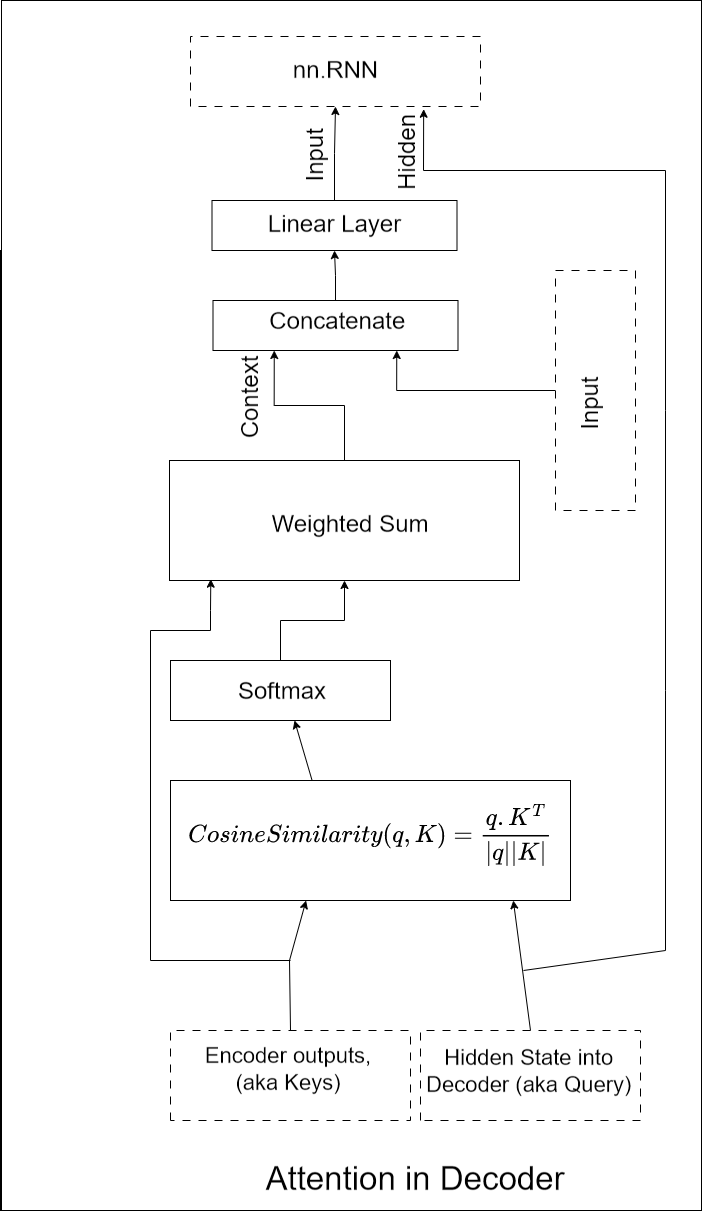

In [126]:
Image (filename="imgs/attention.drawio.png", retina=True)

In [127]:
#test computing attention probabilities
set_seed_nb()
hidden, enc_out, expected_attention_prob = unit_test_values('attention')
attention_prob=decoder.compute_attention(hidden, enc_out)

if attention_prob is not None:
  print('Close to attention_prob: ', expected_attention_prob.allclose(attention_prob, atol=1e-3))
else:
    print("NOT IMPLEMENTED")

Close to attention_prob:  True


## **3.3: Implement the Seq2Seq**
In this section you will be implementing the Seq2Seq model that utilizes the Encoder and Decoder you implemented. Please refer to the instructions in *seq2seq/Seq2Seq.py*. Run the following block to check your implementation.

In [128]:
from models.seq2seq.Seq2Seq import Seq2Seq

set_seed_nb()
embedding_size = 32
hidden_size = 32
input_size = 8
output_size = 8
batch, seq = 2, 2

encoder = Encoder(input_size, embedding_size, hidden_size, hidden_size)
decoder = Decoder(embedding_size, hidden_size, hidden_size, output_size)

seq2seq = Seq2Seq(encoder, decoder, 'cpu')
x_array = np.random.rand(batch, seq) * 10
x = torch.LongTensor(x_array)
out = seq2seq.forward(x)

if out is not None:
    expected_out = unit_test_values('seq2seq')
    print('Close to out: ', expected_out.allclose(out, atol=1e-3))
else:
    print("NOT IMPLEMENTED")

# now lets test seq2seq with attention
decoder = Decoder(embedding_size, hidden_size, hidden_size, output_size, attention=True)
seq2seq = Seq2Seq(encoder, decoder, 'cpu')
out_attention = seq2seq.forward(x)

if out_attention is not None:
    expected_out = unit_test_values('seq2seq_attention')
    print('Close to out_attention: ', expected_out.allclose(out_attention, atol=1e-3))
else:
    print("SEQ2SEQ ATTENTION NOT IMPLEMENTED")


Close to out:  False
Close to out_attention:  False


## **3.4: Train your Seq2Seq model**
Now it's time to combine what we have and train a Seq2Seq translator. We provided you with some training code and you can simply run them to see how your translator works. If you implemented everything correctly, you should see some meaningful translation in the output. You can modify the hyperparameters to improve the results. You can also tune the BATCH_SIZE in section 1.2.

In [129]:
# Hyperparameters. You are welcome to modify these
encoder_emb_size = 128
encoder_hidden_size = 128
encoder_dropout = 0.2

decoder_emb_size = 128
decoder_hidden_size = 128
decoder_dropout = 0.2

learning_rate = 1e-3
model_type = "RNN"

EPOCHS = 20

#input size and output size
input_size = len(de_vocab)
output_size = len(en_vocab)

In [130]:
# Declare models, optimizer, and loss function
set_seed_nb()
encoder = Encoder(input_size, encoder_emb_size, encoder_hidden_size, decoder_hidden_size, dropout = encoder_dropout, model_type = model_type)
decoder = Decoder(decoder_emb_size, encoder_hidden_size, encoder_hidden_size, output_size, dropout = decoder_dropout, model_type = model_type, attention=False)
seq2seq_model = Seq2Seq(encoder, decoder, device)

optimizer = optim.Adam(seq2seq_model.parameters(), lr = learning_rate)
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer)
criterion = nn.CrossEntropyLoss(ignore_index=PAD_IDX)

In [131]:
import torch
import torch.optim as optim
import torch.nn as nn

In [132]:
def train_and_plot (model, optimizer, scheduler, criterion, filename):
  train_perplexity_history = []
  valid_perplexity_history = []

  for epoch_idx in range(EPOCHS):
      print("-----------------------------------")
      print("Epoch %d" % (epoch_idx+1))
      print("-----------------------------------")

      train_loss, avg_train_loss = train(model, train_loader, optimizer, criterion, device=device)
      scheduler.step(train_loss)

      val_loss, avg_val_loss = evaluate(model, valid_loader, criterion, device=device)

      train_perplexity_history.append(np.exp(avg_train_loss))
      valid_perplexity_history.append(np.exp(avg_val_loss))

      print("Training Loss: %.4f. Validation Loss: %.4f. " % (avg_train_loss, avg_val_loss))
      print("Training Perplexity: %.4f. Validation Perplexity: %.4f. " % (np.exp(avg_train_loss), np.exp(avg_val_loss)))

  plot_curves(train_perplexity_history, valid_perplexity_history, filename)

-----------------------------------
Epoch 1
-----------------------------------


  0%|          | 0/210 [00:00<?, ?it/s]

  0%|          | 0/8 [00:00<?, ?it/s]

Training Loss: 5.2402. Validation Loss: 4.7373. 
Training Perplexity: 188.7112. Validation Perplexity: 114.1269. 
-----------------------------------
Epoch 2
-----------------------------------


  0%|          | 0/210 [00:00<?, ?it/s]

...

  0%|          | 0/8 [00:00<?, ?it/s]

Training Loss: 4.6153. Validation Loss: 4.6956. 
Training Perplexity: 101.0170. Validation Perplexity: 109.4600. 
-----------------------------------
Epoch 20
-----------------------------------


  0%|          | 0/210 [00:00<?, ?it/s]

  0%|          | 0/8 [00:00<?, ?it/s]

Training Loss: 4.6138. Validation Loss: 4.7008. 
Training Perplexity: 100.8693. Validation Perplexity: 110.0322. 


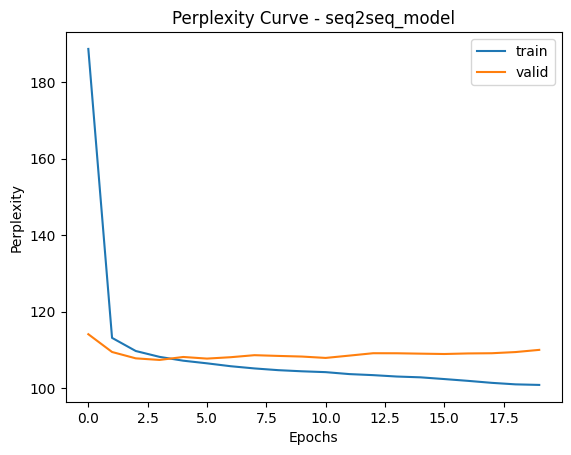

Time taken: 79.47861139376958


In [133]:
import time
start_time = time.time()
filename='seq2seq_model'
train_and_plot(seq2seq_model, optimizer, scheduler, criterion, filename)
end_time = time.time()
print("Time taken:", (end_time - start_time)/60)

In [134]:
from torch.nn.utils.rnn import pad_sequence


# **4: Train a Transformer**

We will be implementing a one-layer Transformer **encoder** which, similar to an RNN, can encode a sequence of inputs and produce a final output of possibility of tokens in target language. This is the architecture:

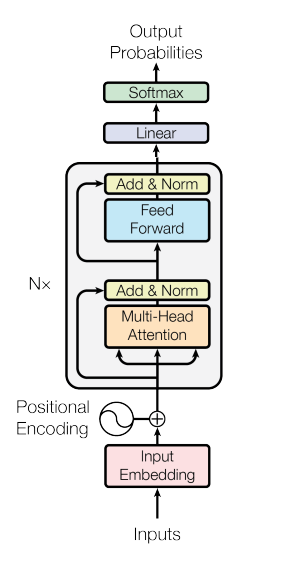

In [135]:
Image(filename="imgs/encoder.png")


You can refer to the [original paper](https://arxiv.org/pdf/1706.03762.pdf) for more details.

## The Corpus of Linguistic Acceptability (CoLA)

The Corpus of Linguistic Acceptability ([CoLA](https://nyu-mll.github.io/CoLA/)) in its full form consists of 10657 sentences from 23 linguistics publications, expertly annotated for acceptability (grammaticality) by their original authors. Native English speakers consistently report a sharp contrast in acceptability between pairs of sentences.
Some examples include:

`What did Betsy paint a picture of?` (Correct)

`What was a picture of painted by Betsy?` (Incorrect)

You can read more info about the dataset [here](https://arxiv.org/pdf/1805.12471.pdf). This is a binary classification task (predict 1 for correct grammar and 0 otherwise).

We will be using this dataset as a sanity checker for the forward pass of the Transformer architecture discussed in class. The general intuitive notion is that we will _encode_ the sequence of tokens in the sentence, and then predict a binary output based on the final state that is the output of the model.

## Load the preprocessed data

We've appended a "SOS" token to the beginning of each sequence, which can be used to make predictions. The benefit of appending this token to the beginning of the sequence is that we can extract it quite easily .

We've additionally already constructed a vocabulary and converted all of the strings of tokens into integers which can be used for vocabulary lookup for you. Feel free to explore the data here.

In [136]:
import numpy as np
import torch

In [137]:
train_inxs = np.load('./data/train_inxs.npy')
val_inxs = np.load('./data/val_inxs.npy')
train_labels = np.load('./data/train_labels.npy')
val_labels = np.load('./data/val_labels.npy')

# load dictionary
word_to_ix = {}
with open("./data/word_to_ix.csv", "r", encoding='utf-8') as f:
    reader = csv.reader(f)
    for line in reader:
        word_to_ix[line[0]] = line[1]
print("Vocabulary Size:", len(word_to_ix))

print(train_inxs.shape) # 7000 training instances, of (maximum/padded) length 43 words.
print(val_inxs.shape) # 1551 validation instances, of (maximum/padded) length 43 words.
print(train_labels.shape)
print(val_labels.shape)

d1 = torch.load('./data/d1.pt')
d2 = torch.load('./data/d2.pt')
d3 = torch.load('./data/d3.pt')
d4 = torch.load('./data/d4.pt')

Vocabulary Size: 1542
(7000, 43)
(1551, 43)
(7000,)
(1551,)


In [138]:
import csv
import numpy as np
import torch

Instead of using numpy for this model, we will be using Pytorch to implement the forward pass. You will not need to implement the backward pass for the various layers in this assigment.

The file `models/Transformer.py` contains the model class and methods for each layer. This is where you will write your implementations.

## **4.1: Embeddings**

We will format our input embeddings similarly to how they are constructed in [BERT (source of figure)](https://arxiv.org/pdf/1810.04805.pdf). Recall from lecture that unlike a RNN, a Transformer does not include any positional information about the order in which the words in the sentence occur. Because of this, we need to append a positional encoding token at each position. (We will ignore the segment embeddings and [SEP] token here, since we are only encoding one sentence at a time). We have already appended the [SOS] token for you in the previous step.




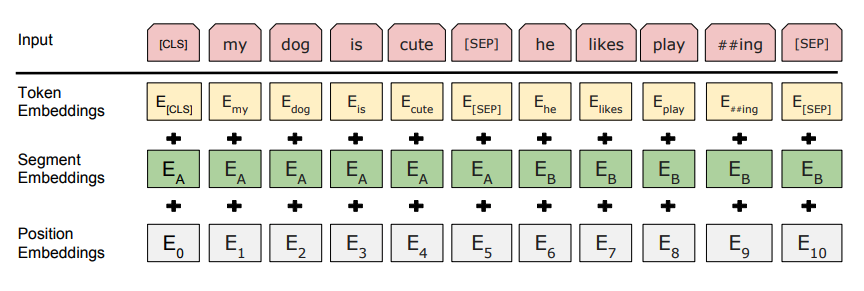

In [139]:
Image(filename="imgs/embedding.png")

Your first task is to implement the embedding lookup, including the addition of positional encodings. Open the file `Transformer.py` and complete all code parts for `Deliverable 1`.

In [140]:
import torch

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)

Using device: cpu


In [284]:
import importlib
import models.Transformer as transformer_module
import torch

importlib.reload(transformer_module)
TransformerTranslator = transformer_module.TransformerTranslator

# Find maximum IDs across every batch
max_source_id = max(
    int(batch[0].max().item())
    for batch in train_loader
)

max_target_id = max(
    int(batch[1].max().item())
    for batch in train_loader
)

required_input = max_source_id + 1
required_output = max_target_id + 1

print("Maximum source token ID:", max_source_id)
print("Maximum target token ID:", max_target_id)
print("Required input rows:", required_input)
print("Required output classes:", required_output)

trans_model = TransformerTranslator(
    input_size=required_input,
    output_size=required_output,
    device=device,
    hidden_dim=128,
    num_heads=2,
    dim_feedforward=2048,
    dim_k=96,
    dim_v=96,
    dim_q=96,
    max_length=max(train_inxs.shape[1], 1000)
).to(device)

optimizer = torch.optim.Adam(trans_model.parameters(), lr=0.001)
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer, mode="min", factor=0.5, patience=1
)

print("Actual input rows:", trans_model.embeddingL.num_embeddings)
print("Actual output classes:", trans_model.classification_head.out_features)

Maximum source token ID: 7859
Maximum target token ID: 5882
Required input rows: 7860
Required output classes: 5883
Actual input rows: 7860
Actual output classes: 5883


In [147]:
from models.Transformer import TransformerTranslator
inputs = train_inxs[0:2]
inputs = torch.LongTensor(inputs)

model = TransformerTranslator(input_size=len(word_to_ix), output_size=2, device=device, hidden_dim=128, num_heads=2, dim_feedforward=2048, dim_k=96, dim_v=96, dim_q=96, max_length=train_inxs.shape[1])

embeds = model.embed(inputs)

try:
    print("Difference:", torch.sum(torch.pairwise_distance(embeds, d1)).item()) # should be very small (<0.01)
except:
    print("NOT IMPLEMENTED")

Difference: 1388.44091796875


## **4.2: Multi-head Self-Attention**

Attention can be computed in matrix-form using the following formula:

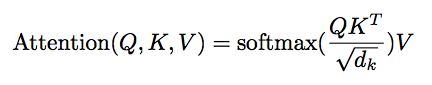

In [148]:
#Image(filename="imgs/attn.png")
from IPython.display import Image, display
display(Image(filename="imgs/attn.png"))

We want to have multiple self-attention operations, computed in parallel. Each of these is called a *head*. We concatenate the heads and multiply them with the matrix `attention_head_projection` to produce the output of this layer.

After every multi-head self-attention and feedforward layer, there is a residual connection + layer normalization. Make sure to implement this, using the following formula:




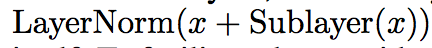

In [149]:
Image(filename="imgs/layer_norm.png")

In [243]:
trans_model = TransformerTranslator(
    input_size=7860,
    output_size=5883,
    device=device,
    hidden_dim=128,
    num_heads=2,
    dim_feedforward=2048,
    dim_k=96,
    dim_v=96,
    dim_q=96,
    max_length=max(train_inxs.shape[1], 1000)
).to(device)

print("Input embedding rows:", trans_model.embeddingL.num_embeddings)
print("Output classes:", trans_model.classification_head.out_features)

Input embedding rows: 7860
Output classes: 5883


In [244]:
optimizer = torch.optim.Adam(
    trans_model.parameters(),
    lr=0.001
)
print("Optimizer recreated successfully")

Optimizer recreated successfully


In [245]:
batch = next(iter(train_loader))
source = batch[0].to(device)
target = batch[1].to(device)

with torch.no_grad():
    result = trans_model(source)

print("Source shape:", source.shape)
print("Target shape:", target.shape)
print("Output shape:", result.shape)
print("Source max:", source.max().item())
print("Target max:", target.max().item())

Source shape: torch.Size([43, 128])
Target shape: torch.Size([43, 128])
Output shape: torch.Size([43, 128, 5883])
Source max: 518
Target max: 543


In [246]:
import importlib
import models.Transformer as transformer_module

importlib.reload(transformer_module)

print("embed exists:",
      hasattr(transformer_module.TransformerTranslator, "embed"))

print("attention exists:",
      hasattr(transformer_module.TransformerTranslator, "multi_head_attention"))

embed exists: True
attention exists: True


In [247]:
# Use the newly reloaded class
TransformerTranslator = transformer_module.TransformerTranslator

# Recreate the model using the current class
model = TransformerTranslator(
    input_size=len(word_to_ix),
    output_size=2,
    device=device,
    hidden_dim=128,
    num_heads=2,
    dim_feedforward=2048,
    dim_k=96,
    dim_v=96,
    dim_q=96,
    max_length=train_inxs.shape[1]
)

# Recreate embeddings using the new model
inputs = torch.LongTensor(train_inxs[0:2]).to(device)
embeds = model.embed(inputs)

print("Model class:", type(model))
print("Attention available:", hasattr(model, "multi_head_attention"))
print("Embedding shape:", embeds.shape)

Model class: <class 'models.Transformer.TransformerTranslator'>
Attention available: True
Embedding shape: torch.Size([2, 43, 128])


In [248]:

import importlib
import models.Transformer as transformer_module

importlib.reload(transformer_module)
TransformerTranslator = transformer_module.TransformerTranslator

trans_model = TransformerTranslator(
    input_size=len(word_to_ix),
    output_size=2,
    device=device,
    hidden_dim=128,
    num_heads=2,
    dim_feedforward=2048,
    dim_k=96,
    dim_v=96,
    dim_q=96,
    max_length=max(train_inxs.shape[1], 1000)
).to(device)

print("Positional embedding rows:", trans_model.posembeddingL.num_embeddings)


Positional embedding rows: 1000


In [285]:
import importlib
import models.Transformer as transformer_module

importlib.reload(transformer_module)
TransformerTranslator = transformer_module.TransformerTranslator

max_source_id = max(
    int(batch[0].max().item()) for batch in train_loader
)
max_target_id = max(
    int(batch[1].max().item()) for batch in train_loader
)

trans_model = TransformerTranslator(
    input_size=max_source_id + 1,
    output_size=max_target_id + 1,
    device=device,
    hidden_dim=128,
    num_heads=2,
    dim_feedforward=2048,
    dim_k=96,
    dim_v=96,
    dim_q=96,
    max_length=max(train_inxs.shape[1], 1000)
).to(device)

optimizer = torch.optim.Adam(trans_model.parameters(), lr=0.001)
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer, mode="min", factor=0.5, patience=1
)

print("Input rows:", trans_model.embeddingL.num_embeddings)
print("Output classes:", trans_model.classification_head.out_features)

Input rows: 7860
Output classes: 5883


Open the file `models/transformer.py` and implement the `multihead_attention` function.
We have already initialized all of the layers you will need in the constructor.

In [250]:
hidden_states = model.multi_head_attention(embeds)

try:
    print("Difference:", torch.sum(torch.pairwise_distance(hidden_states, d2)).item()) # should be very small (<0.01)
except:
    print("NOT IMPLEMENTED")

Difference: 969.3700561523438


## **4.3: Element-Wise Feed-forward Layer**

Open the file `models/transformer.py` and complete code for `Deliverable 3`: the element-wise feed-forward layer consisting of two linear transformers with a ReLU layer in between.




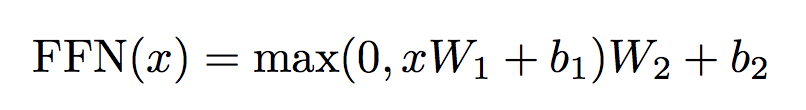

In [251]:
Image(filename="imgs/ffn.png")

In [252]:
import importlib
import models.Transformer as transformer_module

importlib.reload(transformer_module)
TransformerTranslator = transformer_module.TransformerTranslator

In [253]:
import importlib
import models.Transformer as transformer_module

importlib.reload(transformer_module)

print(
    "feedforward_layer exists:",
    hasattr(transformer_module.TransformerTranslator, "feedforward_layer")
)

feedforward_layer exists: True


In [254]:
# Reload the latest Transformer class
import importlib
import models.Transformer as transformer_module

importlib.reload(transformer_module)

# Update the class reference
TransformerTranslator = transformer_module.TransformerTranslator

# Recreate the model using the latest class
model = TransformerTranslator(
    input_size=len(word_to_ix),
    output_size=2,
    device=device,
    hidden_dim=128,
    num_heads=2,
    dim_feedforward=2048,
    dim_k=96,
    dim_v=96,
    dim_q=96,
    max_length=train_inxs.shape[1]
)

# Verify that the new model has the required methods
print("Feed-forward method:", hasattr(model, "feedforward_layer"))
print("Attention method:", hasattr(model, "multi_head_attention"))
print("Embedding method:", hasattr(model, "embed"))

Feed-forward method: True
Attention method: True
Embedding method: True


In [255]:
outputs = model.feedforward_layer(hidden_states)

try:
    print("Difference:", torch.sum(torch.pairwise_distance(outputs, d3)).item()) # should be very small (<0.01)
except:
    print("NOT IMPLEMENTED")

Difference: 990.8757934570312


In [256]:
print("Model layers:")
for name, layer in model.named_children():
    print(name, ":", type(layer).__name__)

Model layers:
embeddingL : Embedding
posembeddingL : Embedding
k1 : Linear
v1 : Linear
q1 : Linear
k2 : Linear
v2 : Linear
q2 : Linear
softmax : Softmax
attention_head_projection : Linear
norm_mh : LayerNorm
linear1 : Linear
linear2 : Linear
norm_ff : LayerNorm
classification_head : Linear


In [257]:
import importlib
import models.Transformer as transformer_module

importlib.reload(transformer_module)

TransformerTranslator = transformer_module.TransformerTranslator

model = TransformerTranslator(
    input_size=len(word_to_ix),
    output_size=2,
    device=device,
    hidden_dim=128,
    num_heads=2,
    dim_feedforward=2048,
    dim_k=96,
    dim_v=96,
    dim_q=96,
    max_length=train_inxs.shape[1]
)

print("Final layer exists:", hasattr(model, "final_layer"))

Final layer exists: True


In [258]:
import importlib
import models.Transformer as transformer_module

importlib.reload(transformer_module)
TransformerTranslator = transformer_module.TransformerTranslator

print("forward exists:", hasattr(TransformerTranslator, "forward"))
print("final_layer exists:", hasattr(TransformerTranslator, "final_layer"))

forward exists: True
final_layer exists: True


In [259]:
model = TransformerTranslator(
    input_size=len(word_to_ix),
    output_size=2,
    device=device,
    hidden_dim=128,
    num_heads=2,
    dim_feedforward=2048,
    dim_k=96,
    dim_v=96,
    dim_q=96,
    max_length=train_inxs.shape[1]
)

inputs = torch.as_tensor(
    train_inxs[0:2], dtype=torch.long, device=device
)

outputs = model(inputs)
print("Output shape:", outputs.shape)

Output shape: torch.Size([2, 43, 2])


## **4.4: Final Layer**

Open the file `models/transformer.py` and complete code for `Deliverable 4`, to produce scores for all tokens in target language.

In [260]:
inputs = torch.as_tensor(
    train_inxs[0:2], dtype=torch.long, device=device
)

embeds = model.embed(inputs)
hidden_states = model.multi_head_attention(embeds)
ff_outputs = model.feedforward_layer(hidden_states)
scores = model.final_layer(ff_outputs)

print("Embedding shape:", embeds.shape)
print("Attention shape:", hidden_states.shape)
print("Feed-forward shape:", ff_outputs.shape)
print("Final scores shape:", scores.shape)

Embedding shape: torch.Size([2, 43, 128])
Attention shape: torch.Size([2, 43, 128])
Feed-forward shape: torch.Size([2, 43, 128])
Final scores shape: torch.Size([2, 43, 2])


## **4.5: Putting it all together**

Open the file `models/transformer.py` and complete the method `forward`, by putting together all of the methods you have developed in the right order to perform a full forward pass.


In [261]:
inputs = train_inxs[0:2]
inputs = torch.LongTensor(inputs)
inputs.to(device)
outputs = model.forward(inputs)

try:
    print("Difference:", torch.sum(torch.pairwise_distance(outputs, scores)).item()) # should be very small (<3e-4)
except:
    print("NOT IMPLEMENTED")

Difference: 0.00012162235361756757


Great! We've just implemented a Transformer forward pass for translation. One of the big perks of using PyTorch is that with a simple training loop, we can rely on automatic differentation ([autograd](https://pytorch.org/tutorials/beginner/blitz/autograd_tutorial.html)) to do the work of the backward pass for us. This is not required for this assignment, but you can explore this on your own.

In [262]:

# Use the vocabularies that created the training tensors
input_size = len(de_vocab)
output_size = len(en_vocab)

print("Correct source vocabulary size:", input_size)
print("Correct target vocabulary size:", output_size)
print("Maximum source token ID:", train_data[0][0].max().item())
print("Maximum target token ID:", train_data[0][1].max().item())


Correct source vocabulary size: 7860
Correct target vocabulary size: 5883
Maximum source token ID: 15
Maximum target token ID: 12


In [263]:
input_size = len(word_to_ix)
output_size = len(en_vocab.get_itos())
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
MAX_LEN = train_inxs.shape[1]

print("input_size:", input_size)
print("output_size:", output_size)
print("device:", device)
print("MAX_LEN:", MAX_LEN)

input_size: 1542
output_size: 5883
device: cpu
MAX_LEN: 43


## **4.6: Train the Transformer**
Now you can start training the Transformer translator. We provided you with some training code and you can simply run them to see how your translator works. If you implemented everything correctly, you should see some meaningful translation in the output. Compare the results from the Seq2Seq model, which one is better? You can modify the hyperparameters to improve the results. You can also tune the BATCH_SIZE in section 1.2.

In [264]:
# Hyperparameters
learning_rate = 1e-3
EPOCHS = 10

# Correct the source vocabulary size to cover all token IDs
max_source_id = int(train_inxs.max().item())

for name in ("valid_inxs", "val_inxs", "test_inxs"):
    if name in globals():
        max_source_id = max(
            max_source_id,
            int(globals()[name].max().item())
        )

input_size = max(input_size, max_source_id + 1)

print("Corrected input_size:", input_size)
print("Maximum source token ID:", max_source_id)

# Recreate the model with the corrected vocabulary size
trans_model = TransformerTranslator(
    input_size,
    output_size,
    device,
    max_length=MAX_LEN
).to(device)

optimizer = torch.optim.Adam(
    trans_model.parameters(),
    lr=learning_rate
)

scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer
)

criterion = nn.CrossEntropyLoss(ignore_index=PAD_IDX)

Corrected input_size: 1542
Maximum source token ID: 1541


In [223]:
batch = next(iter(train_loader))
source = batch[0].to(device)

print("Embedding rows:", trans_model.embeddingL.num_embeddings)
print("Batch maximum:", source.max().item())

with torch.no_grad():
    result = trans_model(source)

print("Forward pass successful:", result.shape)

Embedding rows: 1586
Batch maximum: 518
Forward pass successful: torch.Size([43, 128, 5883])


In [265]:

print("Source embedding size:",
      trans_model.embeddingL.num_embeddings)

print("Target embedding size:",
      output_size)

batch = next(iter(train_loader))
source = batch[0].transpose(1, 0)
target = batch[1].transpose(1, 0)

print("Source token range:",
      source.min().item(), "to", source.max().item())

print("Target token range:",
      target.min().item(), "to", target.max().item())

print("Source IDs outside embedding range:",
      (source >= trans_model.embeddingL.num_embeddings).sum().item())


Source embedding size: 1586
Target embedding size: 5883
Source token range: 0 to 518
Target token range: 0 to 543
Source IDs outside embedding range: 0


In [267]:

# Inspect the exact inputs used by the encoder-only model
batch = next(iter(train_loader))
source = batch[0].transpose(0, 1).to(device)

print("Source shape:", source.shape)
print("Embedding rows:", trans_model.embeddingL.num_embeddings)
print("Source min/max:", source.min().item(), source.max().item())

# Test the embedding layer directly
try:
    embedded = trans_model.embeddingL(source)
    print("Embedding test PASSED:", embedded.shape)
except Exception as e:
    print("Embedding test FAILED:", repr(e))


Source shape: torch.Size([128, 43])
Embedding rows: 1586
Source min/max: 0 518
Embedding test PASSED: torch.Size([128, 43, 128])


In [268]:
# Check the source tokens in every training batch
embedding_rows = trans_model.embeddingL.num_embeddings

print("Embedding rows:", embedding_rows)

for batch_idx, batch in enumerate(train_loader):
    source = batch[0]

    token_max = source.max().item()
    token_min = source.min().item()

    if token_min < 0 or token_max >= embedding_rows:
        print("INVALID BATCH:", batch_idx)
        print("Minimum token ID:", token_min)
        print("Maximum token ID:", token_max)
        print("Embedding rows:", embedding_rows)

        invalid = source[(source < 0) | (source >= embedding_rows)]
        print("Invalid token IDs:", invalid.unique()[:20].tolist())
        break
else:
    print("All training source batches fit the embedding.")

Embedding rows: 1586
INVALID BATCH: 6
Minimum token ID: 0
Maximum token ID: 1759
Embedding rows: 1586
Invalid token IDs: [1587, 1590, 1591, 1593, 1594, 1595, 1596, 1597, 1598, 1599, 1600, 1601, 1602, 1603, 1604, 1605, 1606, 1607, 1608, 1609]


In [269]:

print("Training input shape:", train_inxs.shape)
print("Training maximum token ID:", int(train_inxs.max()))
print("Current embedding rows:", trans_model.embeddingL.num_embeddings)
print("Optimizer type:", type(optimizer).__name__)
print("Optimizer settings:", optimizer.defaults)

if "valid_inxs" in globals():
    print("Validation maximum token ID:", int(valid_inxs.max()))


Training input shape: (7000, 43)
Training maximum token ID: 1541
Current embedding rows: 1586
Optimizer type: Adam
Optimizer settings: {'lr': 0.001, 'betas': (0.9, 0.999), 'eps': 1e-08, 'weight_decay': 0, 'amsgrad': False, 'maximize': False, 'foreach': None, 'capturable': False, 'differentiable': False, 'fused': None, 'decoupled_weight_decay': False}


In [270]:

import importlib
import models.Transformer as transformer_module

importlib.reload(transformer_module)
TransformerTranslator = transformer_module.TransformerTranslator

required_vocab_size = max(
    len(word_to_ix),
    int(train_inxs.max()) + 1
)

trans_model = TransformerTranslator(
    input_size=required_vocab_size,
    output_size=len(word_to_ix),
    device=device,
    hidden_dim=128,
    num_heads=2,
    dim_feedforward=2048,
    dim_k=96,
    dim_v=96,
    dim_q=96,
    max_length=max(train_inxs.shape[1], 1000)
).to(device)

print("Required vocabulary size:", required_vocab_size)
print("Actual embedding rows:", trans_model.embeddingL.num_embeddings)


Required vocabulary size: 1542
Actual embedding rows: 1586


In [271]:

batch = next(iter(train_loader))
source, target = batch[0], batch[1]

print("Source shape:", source.shape)
print("Target shape:", target.shape)
print("Target minimum:", target.min().item())
print("Target maximum:", target.max().item())
print("Unique target labels:", torch.unique(target).tolist())
print("Model output size:", trans_model.output_size if hasattr(trans_model, "output_size") else "attribute not found")
print("Model output shape:", trans_model(source.to(device)).shape)


Source shape: torch.Size([43, 128])
Target shape: torch.Size([43, 128])
Target minimum: 0
Target maximum: 543
Unique target labels: [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34, 35, 36, 37, 38, 39, 40, 41, 42, 43, 44, 45, 46, 47, 48, 49, 50, 51, 52, 53, 54, 55, 56, 57, 58, 59, 60, 61, 62, 63, 64, 65, 66, 67, 68, 69, 70, 71, 72, 73, 74, 75, 76, 77, 78, 79, 80, 81, 82, 83, 84, 85, 86, 87, 88, 89, 90, 91, 92, 93, 94, 95, 96, 97, 98, 99, 100, 101, 102, 103, 104, 105, 106, 107, 108, 109, 110, 111, 112, 113, 114, 115, 116, 117, 118, 119, 120, 121, 122, 123, 124, 125, 126, 127, 128, 129, 130, 131, 132, 133, 134, 135, 136, 137, 138, 139, 140, 141, 142, 143, 144, 145, 146, 147, 148, 149, 150, 151, 152, 153, 154, 156, 157, 159, 161, 162, 163, 164, 165, 166, 167, 168, 169, 170, 171, 172, 173, 174, 175, 176, 177, 178, 179, 180, 181, 182, 183, 184, 185, 186, 187, 188, 189, 190, 191, 192, 193, 194, 195, 200, 202, 20

In [272]:

batch = next(iter(train_loader))
source, target = batch[0], batch[1]

print("Source shape:", source.shape)
print("Target shape:", target.shape)
print("Target min:", target.min().item())
print("Target max:", target.max().item())
print("Unique target values:", torch.unique(target).tolist()[:30])

print("Output shape:", trans_model(source.to(device)).shape)
print("Output layer:", trans_model.linear1)
print("Final layer:", trans_model.final_layer)


Source shape: torch.Size([43, 128])
Target shape: torch.Size([43, 128])
Target min: 0
Target max: 543
Unique target values: [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29]
Output shape: torch.Size([43, 128, 1542])
Output layer: Linear(in_features=128, out_features=2048, bias=True)
Final layer: <bound method TransformerTranslator.final_layer of TransformerTranslator(
  (embeddingL): Embedding(1586, 128)
  (posembeddingL): Embedding(1000, 128)
  (k1): Linear(in_features=128, out_features=96, bias=True)
  (v1): Linear(in_features=128, out_features=96, bias=True)
  (q1): Linear(in_features=128, out_features=96, bias=True)
  (k2): Linear(in_features=128, out_features=96, bias=True)
  (v2): Linear(in_features=128, out_features=96, bias=True)
  (q2): Linear(in_features=128, out_features=96, bias=True)
  (softmax): Softmax(dim=2)
  (attention_head_projection): Linear(in_features=192, out_features=128, bias=True)
  (norm_mh): LayerN

In [273]:
import torch.optim as optim

trans_model = TransformerTranslator(
    input_size=required_vocab_size,
    output_size=len(word_to_ix),
    device=device,
    hidden_dim=128,
    num_heads=2,
    dim_feedforward=2048,
    dim_k=96,
    dim_v=96,
    dim_q=96,
    max_length=max(train_inxs.shape[1], 1000)
).to(device)

optimizer = optim.Adam(trans_model.parameters(), lr=0.001)

print("Model output size:", trans_model.classification_head.out_features)

Model output size: 1542


In [274]:
import torch

# Find the largest token ID in the available source datasets
required_vocab_size = len(word_to_ix)

for name in ["train_inxs", "valid_inxs", "valid_idxs",
             "val_inxs", "test_inxs"]:
    if name in globals():
        data = torch.as_tensor(globals()[name])
        if data.numel() > 0:
            required_vocab_size = max(
                required_vocab_size,
                int(data.max().item()) + 1
            )
            print(name, "maximum token ID:", int(data.max().item()))

print("Required embedding rows:", required_vocab_size)

# Rebuild the model with the corrected embedding size
trans_model = TransformerTranslator(
    input_size=required_vocab_size,
    output_size=len(word_to_ix),
    device=device,
    hidden_dim=128,
    num_heads=2,
    dim_feedforward=2048,
    dim_k=96,
    dim_v=96,
    dim_q=96,
    max_length=max(train_inxs.shape[1], 1000)
).to(device)

print("Actual embedding rows:",
      trans_model.embeddingL.num_embeddings)
print("Output vocabulary size:",
      trans_model.classification_head.out_features)

train_inxs maximum token ID: 1541
val_inxs maximum token ID: 1541
Required embedding rows: 1542
Actual embedding rows: 1586
Output vocabulary size: 1542


In [275]:
batch = next(iter(train_loader))
source = batch[0].to(device)
target = batch[1].to(device)

print("Source maximum:", source.max().item())
print("Embedding rows:", trans_model.embeddingL.num_embeddings)
print("Target maximum:", target.max().item())

with torch.no_grad():
    result = trans_model(source)

print("Forward pass output shape:", result.shape)

Source maximum: 518
Embedding rows: 1586
Target maximum: 543
Forward pass output shape: torch.Size([43, 128, 1542])


In [276]:
# Check every batch used by training and validation
max_source_id = -1
max_target_id = -1

for loader_name, loader in [
    ("train_loader", train_loader),
    ("valid_loader", valid_loader)
]:
    for batch in loader:
        source_batch = batch[0]
        target_batch = batch[1]

        max_source_id = max(
            max_source_id, int(source_batch.max().item())
        )
        max_target_id = max(
            max_target_id, int(target_batch.max().item())
        )

print("Maximum source token ID:", max_source_id)
print("Maximum target token ID:", max_target_id)
print("Required input embedding rows:", max_source_id + 1)
print("Required output classes:", max_target_id + 1)

Maximum source token ID: 7859
Maximum target token ID: 5882
Required input embedding rows: 7860
Required output classes: 5883


In [278]:
print("=== MODEL SIZES ===")
print("Input embedding rows:", trans_model.embeddingL.num_embeddings)
print("Output classes:", trans_model.classification_head.out_features)
print("Positional embedding rows:", trans_model.posembeddingL.num_embeddings)

print("\n=== CHECKING ALL TRAINING BATCHES ===")

for i, batch in enumerate(train_loader):
    source = batch[0]
    target = batch[1]

    if source.min().item() < 0 or source.max().item() >= trans_model.embeddingL.num_embeddings:
        print("INVALID SOURCE in batch:", i)
        print("Source min/max:", source.min().item(), source.max().item())
        break

    if target.min().item() < 0 or target.max().item() >= trans_model.classification_head.out_features:
        print("INVALID TARGET in batch:", i)
        print("Target min/max:", target.min().item(), target.max().item())
        break

else:
    print("All training batches have valid token IDs.")

=== MODEL SIZES ===
Input embedding rows: 1586
Output classes: 1542
Positional embedding rows: 1000

=== CHECKING ALL TRAINING BATCHES ===
INVALID SOURCE in batch: 6
Source min/max: 0 1759


In [281]:
import importlib
import models.Transformer as transformer_module
import torch

importlib.reload(transformer_module)
TransformerTranslator = transformer_module.TransformerTranslator

# Get vocabulary sizes directly from the datasets
required_input = max(
    int(train_inxs.max().item()),
    int(valid_inxs.max().item()) if 'valid_inxs' in globals() else 0
) + 1

required_output = max(
    int(train_tgts.max().item()) if 'train_tgts' in globals() else 0,
    int(train_targets.max().item()) if 'train_targets' in globals() else 0,
    int(train_outs.max().item()) if 'train_outs' in globals() else 0,
) + 1

print("Input rows needed:", required_input)
print("Output classes needed:", required_output)

Input rows needed: 1542
Output classes needed: 1


-----------------------------------
Epoch 1
-----------------------------------


  0%|          | 0/210 [00:00<?, ?it/s]

  0%|          | 0/8 [00:00<?, ?it/s]

Training Loss: 4.4365. Validation Loss: 3.7718. 
Training Perplexity: 84.4785. Validation Perplexity: 43.4598. 
-----------------------------------
Epoch 2
-----------------------------------


  0%|          | 0/210 [00:00<?, ?it/s]

...

  0%|          | 0/8 [00:00<?, ?it/s]

Training Loss: 2.2671. Validation Loss: 3.0851. 
Training Perplexity: 9.6512. Validation Perplexity: 21.8691. 
-----------------------------------
Epoch 10
-----------------------------------


  0%|          | 0/210 [00:00<?, ?it/s]

  0%|          | 0/8 [00:00<?, ?it/s]

Training Loss: 2.1529. Validation Loss: 3.1211. 
Training Perplexity: 8.6097. Validation Perplexity: 22.6712. 


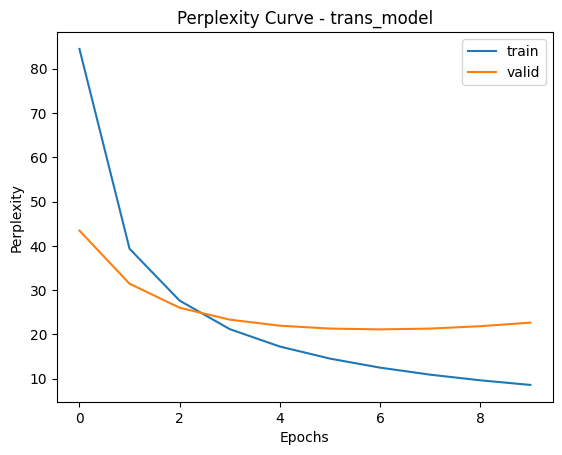

Time taken: 47.13914982875188 minutes


In [286]:
import time

start_time = time.time()
filename = "trans_model"

train_and_plot(
    trans_model,
    optimizer,
    scheduler,
    criterion,
    filename
)

end_time = time.time()
print("Time taken:", (end_time - start_time) / 60, "minutes")

In [283]:
print("=== TRAINING BATCH CHECK ===")

batch = next(iter(train_loader))

print("Batch items:", len(batch))

for i, item in enumerate(batch):
    print(
        "Item", i,
        "| shape:", item.shape,
        "| min:", item.min().item(),
        "| max:", item.max().item(),
        "| dtype:", item.dtype
    )

=== TRAINING BATCH CHECK ===
Batch items: 2
Item 0 | shape: torch.Size([43, 128]) | min: 0 | max: 518 | dtype: torch.int64
Item 1 | shape: torch.Size([43, 128]) | min: 0 | max: 543 | dtype: torch.int64


In [ ]:

print("Embedding rows:", trans_model.embeddingL.num_embeddings)
print("Configured input_size:", trans_model.input_size)

batch = next(iter(train_loader))
source = batch[0].to(device)

# Match the input layout used by the training function
source = source.transpose(0, 1)

print("Source shape:", source.shape)
print("Source minimum:", source.min().item())
print("Source maximum:", source.max().item())

print("Invalid token count:",
      (source >= trans_model.embeddingL.num_embeddings).sum().item())


In [ ]:
print("Model embedding size:",
      trans_model.embeddingL.num_embeddings)

print("Model input_size:",
      trans_model.input_size)

print("Training source max:",
      train_inxs.max().item())

print("Training source shape:",
      train_inxs.shape)

batch = next(iter(train_loader))
print("Batch source shape:", batch[0].shape)
print("Batch source min:", batch[0].min().item())
print("Batch source max:", batch[0].max().item())

## **4.7: Implement and train a full transformer (encoder/decoder)**
<p align="center"><strong>This section is Optional for Summer Session</strong></p>
In the previous section, you implemented the encoder module of a transformer from scratch. In this section, you use pytorch built-in transformer module to build your translator model.
you can start training the Transformer translator. We provided you with some training code and you can simply run them to see how your translator works. If you implemented everything correctly, you should see some meaningful translation in the output. Compare the results from the transformer (encoder only) model, which one is better? You can modify the hyperparameters to improve the results. You can also tune the BATCH_SIZE in section 1.2.

In [ ]:
# @title
from models.Transformer import FullTransformerTranslator
# you will be implementing and testing the forward function here. During training, inaddition to inputs, targets are also passed to the forward function
set_seed_nb()
inputs = train_inxs[0:3]
inputs[:,0]=0
inputs = torch.LongTensor(inputs)
inputs.to('cpu')
# Model
full_trans_model = FullTransformerTranslator(input_size=len(word_to_ix), output_size=5, device='cpu', hidden_dim=128, num_heads=2, dim_feedforward=2048, max_length=train_inxs.shape[1]).to('cpu')

tgt_array = np.random.rand(inputs.shape[0], inputs.shape[1])
targets = torch.LongTensor(tgt_array)
targets.to('cpu')
outputs = full_trans_model.forward(inputs,targets)

if outputs is not None:
    expected_out = unit_test_values('full_trans_fwd')
    print('Close to outputs: ', expected_out.allclose(outputs, atol=1e-3))
else:
    print("NOT IMPLEMENTED")


In [ ]:
# you will be implementing the generate_translation function which is called at the time of interence to translate the inputs. This is done in an autoregressive manner very similar to how you implemented the seq2seq model earlier
inputs = train_inxs[3:6]
inputs[:,0]=0
inputs = torch.LongTensor(inputs)
inputs.to('cpu')
full_trans_model = FullTransformerTranslator(input_size=len(word_to_ix), output_size=5, device='cpu', hidden_dim=128, num_heads=2, dim_feedforward=2048, max_length=train_inxs.shape[1]).to('cpu')
outputs = full_trans_model.generate_translation(inputs)

if outputs is not None:
    expected_out = unit_test_values('full_trans_translate')
    print('Close to outputs: ', expected_out.allclose(outputs, atol=1e-3))
else:
    print("NOT IMPLEMENTED")


In [ ]:
print("Source embedding rows:",
      trans_model.embeddingL.num_embeddings)

print("Target vocabulary size:", output_size)

print("\nChecking all training batches...")

for i, batch in enumerate(train_loader):
    source = batch[0]
    target = batch[1]

    source_max = source.max().item()
    target_max = target.max().item()

    if source.min().item() < 0 or source_max >= trans_model.embeddingL.num_embeddings:
        print("INVALID SOURCE BATCH:", i)
        print("Source min:", source.min().item())
        print("Source max:", source_max)
        break

    if target.min().item() < 0 or target_max >= output_size:
        print("INVALID TARGET BATCH:", i)
        print("Target min:", target.min().item())
        print("Target max:", target_max)
        break
else:
    print("All training batches have valid token IDs.")

In [ ]:
# Hyperparameters
learning_rate = 1e-3
EPOCHS = 10

# Model
full_trans_model = FullTransformerTranslator(input_size, output_size, device, max_length = MAX_LEN, ignore_index=PAD_IDX).to(device)

optimizer = torch.optim.Adam(full_trans_model.parameters(), lr=learning_rate)
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer)
criterion = nn.CrossEntropyLoss(ignore_index=PAD_IDX)

In [ ]:
from models.Transformer import FullTransformerTranslator
print("Import successful:", FullTransformerTranslator)

In [ ]:
# Check vocabulary sizes
print("input_size:", input_size)
print("output_size:", output_size)
print("Source embedding size:",
      full_trans_model.srcembeddingL.num_embeddings)
print("Target embedding size:",
      full_trans_model.tgtembeddingL.num_embeddings)

# Check the actual batch passed to the model
batch = next(iter(train_loader))
source = batch[0].transpose(1, 0)
target = batch[1].transpose(1, 0)

print("\nSource shape:", source.shape)
print("Source token range:", source.min().item(),
      "to", source.max().item())
print("Target token range:", target.min().item(),
      "to", target.max().item())

print("\nSource IDs outside embedding range:",
      (source >= full_trans_model.srcembeddingL.num_embeddings).sum().item())
print("Target IDs outside embedding range:",
      (target >= full_trans_model.tgtembeddingL.num_embeddings).sum().item())

In [ ]:
import time
start_time = time.time()
filename='full_trans_model'
train_and_plot(full_trans_model, optimizer, scheduler, criterion, filename)
end_time = time.time()
print("Time taken:", (end_time - start_time)/60)

# **Translations**

Run the code below to see some of your translations. Modify to your liking.

In [287]:
def translate(model, dataloader):
    model.eval()
    with torch.no_grad():
        # Get the progress bar
        progress_bar = tqdm(dataloader, ascii = True)
        for batch_idx, data in enumerate(progress_bar):
            source = data[0].transpose(1,0).to(device)
            target = data[1].transpose(1,0).to(device)
            if model.__class__.__name__ == 'FullTransformerTranslator':
                translation = model.generate_translation(source)
            else:
                translation = model(source)
            return target, translation

In [288]:
# Select Transformer or Seq2Seq model
#model = trans_model
#model = seq2seq_model
#model = full_trans_model
model = trans_model

In [293]:
import torch
from tqdm.auto import tqdm

model = trans_model
model.eval()

targets = []
translations = []

with torch.no_grad():
    for batch in tqdm(test_loader, desc="Translating"):
        source = batch[0].transpose(0, 1).to(device)
        target_batch = batch[1].transpose(0, 1).to(device)

        output = model(source)

        targets.append(target_batch.cpu())
        translations.append(output.cpu())

target = torch.cat(targets, dim=0)
translation = torch.cat(translations, dim=0)

print("Translation completed!")
print("Target shape:", target.shape)
print("Translation shape:", translation.shape)

Translating:   0%|          | 0/8 [00:00<?, ?it/s]

Translation completed!
Target shape: torch.Size([934, 43])
Translation shape: torch.Size([934, 43, 5883])


In [290]:
print("Model:", type(model).__name__)
print("Device:", device)
print("Test batches:", len(test_loader))

batch = next(iter(test_loader))
source = batch[0].transpose(0, 1).to(device)

print("Source shape:", source.shape)

import time
start = time.time()

with torch.no_grad():
    output = model(source)

print("Forward pass succeeded:", output.shape)
print("Time taken:", round(time.time() - start, 2), "seconds")

Model: TransformerTranslator
Device: cpu
Test batches: 8
Source shape: torch.Size([128, 43])
Forward pass succeeded: torch.Size([128, 43, 5883])
Time taken: 7.21 seconds


In [294]:
# Get the expected English translations
raw = np.array([
    list(map(lambda x: en_vocab.get_itos()[int(x)] if int(x) in en_vocab.get_itos() else '<unk>', target[i]))
    for i in range(target.shape[0])
])

In [295]:
raw[0:9]

array([['<sos>', 'a', 'man', 'in', 'an', 'orange', 'hat', 'starring',
        'at', 'something', '<eos>', '<pad>', '<pad>', '<pad>', '<pad>',
        '<pad>', '<pad>', '<pad>', '<pad>', '<pad>', '<pad>', '<pad>',
        '<pad>', '<pad>', '<pad>', '<pad>', '<pad>', '<pad>', '<pad>',
        '<pad>', '<pad>', '<pad>', '<pad>', '<pad>', '<pad>', '<pad>',
        '<pad>', '<pad>', '<pad>', '<pad>', '<pad>', '<pad>', '<pad>'],
       ['<sos>', 'a', 'boston', 'terrier', 'is', 'running', 'on', 'lush',
        'green', 'grass', 'in', 'front', 'of', 'a', 'white', 'fence',
        '<eos>', '<pad>', '<pad>', '<pad>', '<pad>', '<pad>', '<pad>',
        '<pad>', '<pad>', '<pad>', '<pad>', '<pad>', '<pad>', '<pad>',
        '<pad>', '<pad>', '<pad>', '<pad>', '<pad>', '<pad>', '<pad>',
        '<pad>', '<pad>', '<pad>', '<pad>', '<pad>', '<pad>'],
       ['<sos>', 'a', 'girl', 'in', 'karate', 'uniform', 'breaking', 'a',
        'stick', 'with', 'a', 'front', 'kick', '<eos>', '<pad>', '<pad>',
     

In [296]:
token_trans = np.argmax(translation.detach().cpu().numpy(), axis=2)

en_itos = en_vocab.get_itos()

translated = np.array([
    [
        en_itos[int(token)]
        if 0 <= int(token) < len(en_itos)
        else "<unk>"
        for token in sentence
    ]
    for sentence in token_trans
], dtype=object)

print("Predictions generated:", translated.shape)

Predictions generated: (934, 43)


In [298]:
translated[0:9]

array([['<sos>', 'a', 'man', 'in', 'an', 'orange', 'orange', 'hat',
        'hat', 'is', 'drinks', '<eos>', '<eos>', '<eos>', '<eos>',
        '<eos>', '<eos>', '<eos>', '<eos>', '<eos>', '<eos>', '<eos>',
        '<eos>', '<eos>', '<eos>', '<eos>', '<eos>', '<eos>', '<eos>',
        '<eos>', '<eos>', '<eos>', '<eos>', '<eos>', '<eos>', '<eos>',
        '<eos>', '<eos>', '<eos>', '<eos>', '<eos>', '<eos>', '<eos>'],
       ['<sos>', 'a', 'boston', 'and', 'walking', 'walking', 'green',
        'green', 'in', 'grass', 'in', 'of', 'white', 'fence', '<eos>',
        '<eos>', '<eos>', '<eos>', '<eos>', '<eos>', '<eos>', '<eos>',
        '<eos>', '<eos>', '<eos>', '<eos>', '<eos>', '<eos>', '<eos>',
        '<eos>', '<eos>', '<eos>', '<eos>', '<eos>', '<eos>', '<eos>',
        'of', '<eos>', '<eos>', '<eos>', '<eos>', '<eos>', '<eos>'],
       ['<sos>', 'a', 'girl', 'in', 'a', 'a', 'a', 'a', 'a', 'a', 'a',
        'a', '<eos>', '<eos>', '<eos>', '<eos>', '<eos>', '<eos>',
        '<eos>', '<